In [2]:
!pip install torch torchvision torchaudio
!pip install transformers datasets accelerate
!pip install scikit-learn pandas numpy matplotlib seaborn
!pip install optuna tqdm scipy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
INFO: pip is looking at multiple versions of datasets to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 9.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 30.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 103.9 MB/s  0:00:00 eta 0:00:010:00:01
  Attempting uninstall: fsspec╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/14 [multidict]
    Found existing installation: fsspec 2026.7.0━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  3/14 [multidict]
    Uninstalling fsspec-2026.7.0:╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━  4/14 [fsspec]idict]
      Successfully uninstalled fsspec-2026.7.00m━━━━━━━━━━━━━━━━━━━━━━━━━━━━  4/14 [fsspec]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14/14 [accelerate]0m 13/14 [accelerate]iprocess]

[notice] A new release of pip is available: 26.2

In [3]:
import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm

# Reproducibility
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

/homes/nna272/anaconda3/envs/breast_cancer/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.13.0+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 3080
GPU Memory: 9.61 GB


In [4]:
# Data loader
DATA_PATH = "/homes/nna272/Desktop/Clinical and sociodemographic data on congenital syphilis cases, Brazil, 2013-2021./Clinical and sociodemographic data on congenital syphilis cases, Brazil, 2013-2021/data_set.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nDataset statistics:")
display(df.describe(include="all").T)

Dataset shape: (41762, 26)

Column names:
['VDRL_RESULT', 'CONS_ALCOHOL', 'RH_FACTOR', 'SMOKER', 'PLAN_PREGNANCY', 'BLOOD_GROUP', 'HAS_PREG_RISK', 'TET_VACCINE', 'IS_HEAD_FAMILY', 'MARITAL_STATUS', 'FOOD_INSECURITY', 'NUM_ABORTIONS', 'NUM_LIV_CHILDREN', 'NUM_PREGNANCIES', 'FAM_PLANNING', 'TYPE_HOUSE', 'HAS_FAM_INCOME', 'LEVEL_SCHOOLING', 'CONN_SEWER_NET', 'NUM_RES_HOUSEHOLD', 'HAS_FRU_TREE', 'HAS_VEG_GARDEN', 'FAM_INCOME', 'HOUSING_STATUS', 'WATER_TREATMENT', 'AGE']

First 5 records:


,VDRL_RESULT,CONS_ALCOHOL,RH_FACTOR,SMOKER,PLAN_PREGNANCY,BLOOD_GROUP,HAS_PREG_RISK,TET_VACCINE,IS_HEAD_FAMILY,MARITAL_STATUS,...,HAS_FAM_INCOME,LEVEL_SCHOOLING,CONN_SEWER_NET,NUM_RES_HOUSEHOLD,HAS_FRU_TREE,HAS_VEG_GARDEN,FAM_INCOME,HOUSING_STATUS,WATER_TREATMENT,AGE
0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,...,0.0,5.0,0.0,2.0,1.0,1.0,0.0,1.0,2.0,25.0
1,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,5.0,...,0.0,5.0,0.0,2.0,1.0,1.0,2.0,1.0,3.0,25.0
2,1.0,1.0,2.0,1.0,1.0,4.0,1.0,0.0,1.0,5.0,...,1.0,6.0,2.0,4.0,1.0,1.0,3.0,0.0,3.0,24.0
3,1.0,1.0,2.0,1.0,0.0,4.0,0.0,0.0,1.0,5.0,...,0.0,2.0,1.0,3.0,1.0,1.0,0.0,0.0,2.0,28.0
4,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,...,1.0,4.0,1.0,3.0,1.0,1.0,0.0,0.0,3.0,27.0



Data types:
VDRL_RESULT          float64
CONS_ALCOHOL         float64
RH_FACTOR            float64
SMOKER               float64
PLAN_PREGNANCY       float64
BLOOD_GROUP          float64
HAS_PREG_RISK        float64
TET_VACCINE          float64
IS_HEAD_FAMILY       float64
MARITAL_STATUS       float64
FOOD_INSECURITY      float64
NUM_ABORTIONS        float64
NUM_LIV_CHILDREN     float64
NUM_PREGNANCIES      float64
FAM_PLANNING         float64
TYPE_HOUSE           float64
HAS_FAM_INCOME       float64
LEVEL_SCHOOLING      float64
CONN_SEWER_NET       float64
NUM_RES_HOUSEHOLD    float64
HAS_FRU_TREE         float64
HAS_VEG_GARDEN       float64
FAM_INCOME           float64
HOUSING_STATUS       float64
WATER_TREATMENT      float64
AGE                  float64
dtype: object

Missing values:
VDRL_RESULT          0
CONS_ALCOHOL         0
RH_FACTOR            0
SMOKER               0
PLAN_PREGNANCY       0
BLOOD_GROUP          0
HAS_PREG_RISK        0
TET_VACCINE          0
IS_HEAD_FAMILY    

,count,mean,std,min,25%,50%,75%,max
VDRL_RESULT,41762.0,0.980221,0.139241,0.0,1.0,1.0,1.0,1.0
CONS_ALCOHOL,41762.0,1.068890,0.353034,0.0,1.0,1.0,1.0,2.0
RH_FACTOR,41762.0,0.714789,0.931219,0.0,0.0,0.0,2.0,2.0
SMOKER,41762.0,1.040683,0.331452,0.0,1.0,1.0,1.0,2.0
PLAN_PREGNANCY,41762.0,0.648700,0.573161,0.0,0.0,1.0,1.0,2.0
BLOOD_GROUP,41762.0,1.810474,1.676994,0.0,0.0,1.0,4.0,4.0
HAS_PREG_RISK,41762.0,0.918299,0.412945,0.0,1.0,1.0,1.0,2.0
TET_VACCINE,41762.0,0.164911,0.475779,0.0,0.0,0.0,0.0,2.0
IS_HEAD_FAMILY,41762.0,0.960251,0.499563,0.0,1.0,1.0,1.0,2.0
MARITAL_STATUS,41762.0,2.380657,2.284152,0.0,0.0,1.0,5.0,5.0


In [6]:
# Examining columns that might represent labels or patient IDs.
for col in df.columns:

    if any(x in col.lower() for x in
           ["label", "target", "diagnosis", "syphilis", "outcome"]):

        print(f"\nPossible target column: {col}")
        print(df[col].value_counts(dropna=False))

    if any(x in col.lower() for x in
           ["patient", "subject", "person", "case"]):

        
        print(f"\nPossible patient identifier: {col}")
        print("Unique values:", df[col].nunique())

In [7]:
# Target distribution
print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

target = "VDRL_RESULT"

print(df[target].value_counts(dropna=False))
print("\nPercentage distribution:")
print(df[target].value_counts(normalize=True) * 100)

# Unique values in every column
print("\n" + "=" * 60)
print("FEATURE CARDINALITY")
print("=" * 60)

for col in df.columns:
    print(
        f"{col:25s} | "
        f"Unique: {df[col].nunique():3d} | "
        f"Values: {sorted(df[col].unique().tolist())}"
    )

# Negative values
print("\n" + "=" * 60)
print("NEGATIVE VALUES")
print("=" * 60)

for col in df.columns:
    count = (df[col] < 0).sum()

    if count > 0:
        print(f"{col}: {count} negative values")

# Duplicate analysis
print("\n" + "=" * 60)
print("DUPLICATE ANALYSIS")
print("=" * 60)

print("Total records:", len(df))
print("Exact duplicate records:", df.duplicated().sum())
print("Unique records:", len(df.drop_duplicates()))

# Target distribution across duplicate records
print("\nTarget distribution among duplicated rows:")

duplicate_rows = df[df.duplicated(keep=False)]

if len(duplicate_rows) > 0:
    print(duplicate_rows[target].value_counts())

# Correlation with target
print("\n" + "=" * 60)
print("FEATURE CORRELATION WITH TARGET")
print("=" * 60)

correlations = (
    df.corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

print(correlations)

TARGET DISTRIBUTION
VDRL_RESULT
1.0    40936
0.0      826
Name: count, dtype: int64

Percentage distribution:
VDRL_RESULT
1.0    98.022125
0.0     1.977875
Name: proportion, dtype: float64

FEATURE CARDINALITY
VDRL_RESULT               | Unique:   2 | Values: [0.0, 1.0]
CONS_ALCOHOL              | Unique:   3 | Values: [0.0, 1.0, 2.0]
RH_FACTOR                 | Unique:   3 | Values: [0.0, 1.0, 2.0]
SMOKER                    | Unique:   3 | Values: [0.0, 1.0, 2.0]
PLAN_PREGNANCY            | Unique:   3 | Values: [0.0, 1.0, 2.0]
BLOOD_GROUP               | Unique:   5 | Values: [0.0, 1.0, 2.0, 3.0, 4.0]
HAS_PREG_RISK             | Unique:   3 | Values: [0.0, 1.0, 2.0]
TET_VACCINE               | Unique:   3 | Values: [0.0, 1.0, 2.0]
IS_HEAD_FAMILY            | Unique:   3 | Values: [0.0, 1.0, 2.0]
MARITAL_STATUS            | Unique:   6 | Values: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
FOOD_INSECURITY           | Unique:   3 | Values: [0.0, 1.0, 2.0]
NUM_ABORTIONS             | Unique:   4 | Va

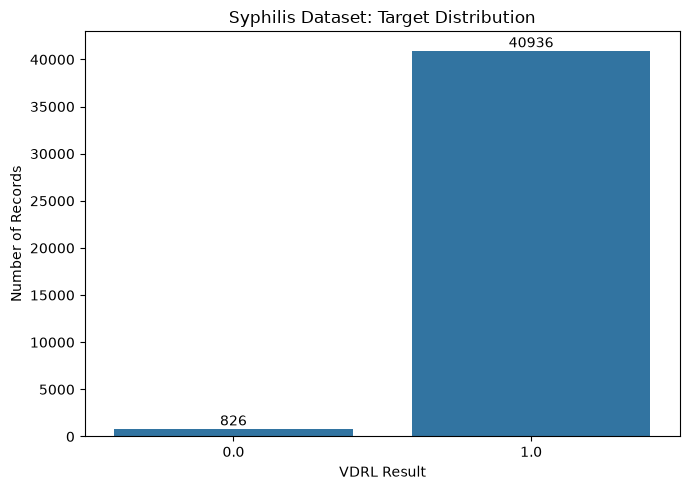

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="VDRL_RESULT"
)

plt.title("Syphilis Dataset: Target Distribution")
plt.xlabel("VDRL Result")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [9]:
FEATURES = [
    col for col in df.columns
    if col != "VDRL_RESULT"
]

# Group records by identical input features
grouped = df.groupby(FEATURES, dropna=False)["VDRL_RESULT"]

conflicts = grouped.nunique()
conflicts = conflicts[conflicts > 1]

print("Identical feature combinations:", len(grouped))
print("Conflicting feature combinations:", len(conflicts))

if len(conflicts) > 0:
    print("\nExamples of conflicting combinations:")
    print(conflicts.head(20))

# Number of records belonging to conflicting groups
if len(conflicts) > 0:
    conflict_records = (
        df.set_index(FEATURES)
        .loc[conflicts.index]
        .reset_index()
    )

    print("\nRecords involved in conflicts:", len(conflict_records))
    display(conflict_records.head(20))

Identical feature combinations: 40912
Conflicting feature combinations: 17

Examples of conflicting combinations:
CONS_ALCOHOL  RH_FACTOR  SMOKER  PLAN_PREGNANCY  BLOOD_GROUP  HAS_PREG_RISK  TET_VACCINE  IS_HEAD_FAMILY  MARITAL_STATUS  FOOD_INSECURITY  NUM_ABORTIONS  NUM_LIV_CHILDREN  NUM_PREGNANCIES  FAM_PLANNING  TYPE_HOUSE  HAS_FAM_INCOME  LEVEL_SCHOOLING  CONN_SEWER_NET  NUM_RES_HOUSEHOLD  HAS_FRU_TREE  HAS_VEG_GARDEN  FAM_INCOME  HOUSING_STATUS  WATER_TREATMENT  AGE 
0.0           0.0        1.0     1.0             1.0          1.0            0.0          1.0             5.0             2.0              0.0            1.0               1.0              0.0           4.0         1.0             5.0              0.0             4.0                1.0           1.0             3.0         0.0             0.0              25.0    2
1.0           0.0        1.0     0.0             0.0          0.0            0.0          1.0             5.0             0.0              3.0            4

,CONS_ALCOHOL,RH_FACTOR,SMOKER,PLAN_PREGNANCY,BLOOD_GROUP,HAS_PREG_RISK,TET_VACCINE,IS_HEAD_FAMILY,MARITAL_STATUS,FOOD_INSECURITY,...,LEVEL_SCHOOLING,CONN_SEWER_NET,NUM_RES_HOUSEHOLD,HAS_FRU_TREE,HAS_VEG_GARDEN,FAM_INCOME,HOUSING_STATUS,WATER_TREATMENT,AGE,VDRL_RESULT
0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,5.0,2.0,...,5.0,0.0,4.0,1.0,1.0,3.0,0.0,0.0,25.0,0.0
1,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,5.0,2.0,...,5.0,0.0,4.0,1.0,1.0,3.0,0.0,0.0,25.0,1.0
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,5.0,0.0,...,5.0,0.0,4.0,1.0,1.0,2.0,0.0,3.0,25.0,0.0
3,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,5.0,0.0,...,5.0,0.0,4.0,1.0,1.0,2.0,0.0,3.0,25.0,1.0
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,5.0,0.0,...,5.0,0.0,4.0,1.0,1.0,2.0,0.0,3.0,25.0,1.0
5,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,...,5.0,0.0,2.0,1.0,1.0,1.0,0.0,2.0,25.0,0.0
6,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,...,5.0,0.0,2.0,1.0,1.0,1.0,0.0,2.0,25.0,1.0
7,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,...,5.0,0.0,3.0,1.0,1.0,0.0,0.0,2.0,25.0,1.0
8,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,...,5.0,0.0,3.0,1.0,1.0,0.0,0.0,2.0,25.0,0.0
9,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,...,6.0,0.0,4.0,1.0,1.0,1.0,0.0,2.0,25.0,1.0


In [10]:
print("Target labels:")
print(df["VDRL_RESULT"].value_counts())

print("\nAge statistics:")
print(df["AGE"].describe())

print("\nInvalid or suspicious age records:")
display(df[df["AGE"] < 0])

print("\nAge frequency:")
print(df["AGE"].value_counts().sort_index())

Target labels:
VDRL_RESULT
1.0    40936
0.0      826
Name: count, dtype: int64

Age statistics:
count    41762.000000
mean        25.191729
std          4.561691
min         -3.000000
25%         25.000000
50%         25.000000
75%         25.000000
max         51.000000
Name: AGE, dtype: float64

Invalid or suspicious age records:


,VDRL_RESULT,CONS_ALCOHOL,RH_FACTOR,SMOKER,PLAN_PREGNANCY,BLOOD_GROUP,HAS_PREG_RISK,TET_VACCINE,IS_HEAD_FAMILY,MARITAL_STATUS,...,HAS_FAM_INCOME,LEVEL_SCHOOLING,CONN_SEWER_NET,NUM_RES_HOUSEHOLD,HAS_FRU_TREE,HAS_VEG_GARDEN,FAM_INCOME,HOUSING_STATUS,WATER_TREATMENT,AGE
11939,1.0,1.0,2.0,1.0,1.0,4.0,1.0,0.0,1.0,5.0,...,0.0,2.0,1.0,4.0,1.0,1.0,3.0,0.0,4.0,-3.0



Age frequency:
AGE
-3.0         1
 0.0        31
 1.0         2
 2.0         2
 3.0         2
 4.0         1
 5.0         2
 7.0         2
 11.0        1
 12.0        2
 13.0       29
 14.0      144
 15.0      350
 16.0      629
 17.0      785
 18.0     1011
 19.0     1148
 20.0     1238
 21.0     1171
 22.0     1238
 23.0     1194
 24.0     1195
 25.0    22017
 26.0     1096
 27.0     1115
 28.0      992
 29.0      925
 30.0      883
 31.0      763
 32.0      705
 33.0      583
 34.0      549
 35.0      405
 36.0      360
 37.0      298
 38.0      219
 39.0      219
 40.0      171
 41.0      100
 42.0       70
 43.0       44
 44.0       33
 45.0       19
 46.0        5
 47.0        4
 48.0        6
 49.0        1
 50.0        1
 51.0        1
Name: count, dtype: int64


In [11]:
import pandas as pd
import numpy as np
import torch

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler


# CONFIG

TARGET_COL = "VDRL_RESULT"

df = df.copy().reset_index(drop=True)


FEATURE_COLS = [c for c in df.columns if c != TARGET_COL]
NUMERIC_COLS = ["AGE"]
CATEGORICAL_COLS = [
    c for c in FEATURE_COLS
    if c not in NUMERIC_COLS
]
assert set(df[TARGET_COL].unique()) == {0.0, 1.0}

# Convert target 0-1
df[TARGET_COL] = df[TARGET_COL].astype(np.int64)


df.loc[df["AGE"] < 0, "AGE"] = np.nan
groups = pd.util.hash_pandas_object(
    df[FEATURE_COLS],
    index=False
).to_numpy()

y = df[TARGET_COL].to_numpy()

print("Total records:", len(df))
print("Categorical features:", len(CATEGORICAL_COLS))
print("Numerical features:", len(NUMERIC_COLS))
print("Unique feature groups:", len(np.unique(groups)))

print("\nTarget distribution:")
print(df[TARGET_COL].value_counts())

Total records: 41762
Categorical features: 24
Numerical features: 1
Unique feature groups: 40912

Target distribution:
VDRL_RESULT
1    40936
0      826
Name: count, dtype: int64


In [12]:
# Test train split
outer_cv = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_pool_idx, test_idx = next(
    outer_cv.split(
        df,
        y,
        groups
    )
)


train_pool = df.iloc[train_pool_idx].reset_index(drop=True)

pool_groups = groups[train_pool_idx]
pool_y = train_pool[TARGET_COL].to_numpy()

inner_cv = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    inner_cv.split(
        train_pool,
        pool_y,
        pool_groups
    )
)

train_df = train_pool.iloc[train_idx].reset_index(drop=True)
val_df = train_pool.iloc[val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)


def show_distribution(name, data):
    print(f"\n{name}")
    print("Records:", len(data))

    print(
        data[TARGET_COL]
        .value_counts()
        .sort_index()
    )

    print(
        "Class percentages:",
        (data[TARGET_COL].value_counts(normalize=True) * 100)
        .round(3).to_dict()
    )

show_distribution("TRAIN", train_df)
show_distribution("VALIDATION", val_df)
show_distribution("TEST", test_df)
train_groups = set(groups[train_pool_idx][train_idx])
val_groups = set(groups[train_pool_idx][val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("\nNo identical feature groups cross the splits.")


TRAIN
Records: 29830
VDRL_RESULT
0      590
1    29240
Name: count, dtype: int64
Class percentages: {1: 98.022, 0: 1.978}

VALIDATION
Records: 5965
VDRL_RESULT
0     118
1    5847
Name: count, dtype: int64
Class percentages: {1: 98.022, 0: 1.978}

TEST
Records: 5967
VDRL_RESULT
0     118
1    5849
Name: count, dtype: int64
Class percentages: {1: 98.022, 0: 1.978}

No identical feature groups cross the splits.


In [14]:
import pickle
age_median = train_df["AGE"].median()

train_age = train_df["AGE"].fillna(age_median).to_numpy()
val_age = val_df["AGE"].fillna(age_median).to_numpy()
test_age = test_df["AGE"].fillna(age_median).to_numpy()

age_scaler = StandardScaler()

train_age = age_scaler.fit_transform(
    train_age.reshape(-1, 1)
).astype(np.float32)

val_age = age_scaler.transform(
    val_age.reshape(-1, 1)
).astype(np.float32)

test_age = age_scaler.transform(
    test_age.reshape(-1, 1)
).astype(np.float32)


# CATEGORICAL ENCODING

category_maps = {}
category_cardinalities = {}

for col in CATEGORICAL_COLS:

    # Vocabulary learned only from training data.
    unique_values = sorted(
        train_df[col].dropna().unique().tolist()
    )

    # 0 reserved for unknown categories.
    mapping = {
        value: idx + 1
        for idx, value in enumerate(unique_values)
    }

    category_maps[col] = mapping

    # Include index 0 in the embedding vocabulary.
    category_cardinalities[col] = len(mapping) + 1


def encode_categorical(data):

    encoded = np.zeros(
        (len(data), len(CATEGORICAL_COLS)),
        dtype=np.int64
    )

    for j, col in enumerate(CATEGORICAL_COLS):

        encoded[:, j] = (
            data[col]
            .map(category_maps[col])
            .fillna(0)
            .astype(np.int64)
            .to_numpy()
        )

    return encoded


X_train_cat = encode_categorical(train_df)
X_val_cat = encode_categorical(val_df)
X_test_cat = encode_categorical(test_df)

y_train = train_df[TARGET_COL].to_numpy(dtype=np.int64)
y_val = val_df[TARGET_COL].to_numpy(dtype=np.int64)
y_test = test_df[TARGET_COL].to_numpy(dtype=np.int64)

print("Training categorical shape:", X_train_cat.shape)
print("Validation categorical shape:", X_val_cat.shape)
print("Test categorical shape:", X_test_cat.shape)

print("\nCategorical cardinalities:")
print(category_cardinalities)

# Save preprocessing artifacts
os.makedirs("task1_syphilis", exist_ok=True)

preprocessing_artifacts = {
    "categorical_columns": CATEGORICAL_COLS,
    "numeric_columns": NUMERIC_COLS,
    "category_maps": category_maps,
    "category_cardinalities": category_cardinalities,
    "age_median": age_median,
    "age_scaler": age_scaler,
}

with open(
    "task1_syphilis/preprocessing.pkl",
    "wb"
) as f:
    pickle.dump(preprocessing_artifacts, f)

Training categorical shape: (29830, 24)
Validation categorical shape: (5965, 24)
Test categorical shape: (5967, 24)

Categorical cardinalities:
{'CONS_ALCOHOL': 4, 'RH_FACTOR': 4, 'SMOKER': 4, 'PLAN_PREGNANCY': 4, 'BLOOD_GROUP': 6, 'HAS_PREG_RISK': 4, 'TET_VACCINE': 4, 'IS_HEAD_FAMILY': 4, 'MARITAL_STATUS': 7, 'FOOD_INSECURITY': 4, 'NUM_ABORTIONS': 5, 'NUM_LIV_CHILDREN': 6, 'NUM_PREGNANCIES': 6, 'FAM_PLANNING': 4, 'TYPE_HOUSE': 7, 'HAS_FAM_INCOME': 3, 'LEVEL_SCHOOLING': 11, 'CONN_SEWER_NET': 4, 'NUM_RES_HOUSEHOLD': 7, 'HAS_FRU_TREE': 4, 'HAS_VEG_GARDEN': 4, 'FAM_INCOME': 5, 'HOUSING_STATUS': 5, 'WATER_TREATMENT': 6}


In [15]:
from torch.utils.data import TensorDataset


# CREATING TENSORS

X_train_age = train_age
X_val_age = val_age
X_test_age = test_age


def make_dataset(X_cat, X_age, y):

    return TensorDataset(
        torch.tensor(X_cat, dtype=torch.long),
        torch.tensor(X_age, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )


train_dataset = make_dataset(
    X_train_cat,
    X_train_age,
    y_train
)

val_dataset = make_dataset(
    X_val_cat,
    X_val_age,
    y_val
)

test_dataset = make_dataset(
    X_test_cat,
    X_test_age,
    y_test
)


# WEIGHTED RANDOM SAMPLER

class_counts = np.bincount(
    y_train,
    minlength=2
)

class_weights = 1.0 / class_counts

sample_weights = class_weights[y_train]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(y_train),
    replacement=True
)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Validation and test 
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training class counts:", class_counts)
print("Training batches:", len(train_loader))

# Verifing sampling distribution.
sampled_labels = []

for _, _, labels in train_loader:
    sampled_labels.extend(labels.numpy())

print("\nWeighted sampled distribution:")
print(pd.Series(sampled_labels).value_counts(normalize=True))

Training class counts: [  590 29240]
Training batches: 117

Weighted sampled distribution:
1    0.501676
0    0.498324
Name: proportion, dtype: float64


In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class SyphilisTabularModel(nn.Module):

    def __init__(
        self,
        category_cardinalities,
        hidden_dim=128,
        representation_dim=128,
        dropout=0.3
    ):
        super().__init__()

        self.num_categories = len(category_cardinalities)

        self.embeddings = nn.ModuleList()

        embedding_dims = []

        for cardinality in category_cardinalities:

            emb_dim = min(
                16,
                max(4, int(math.ceil(math.sqrt(cardinality))))
            )

            embedding_dims.append(emb_dim)

            self.embeddings.append(
                nn.Embedding(
                    num_embeddings=cardinality,
                    embedding_dim=emb_dim,
                    padding_idx=0
                )
            )

        total_embedding_dim = sum(embedding_dims)

        self.age_projection = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU()
        )

        input_dim = total_embedding_dim + 16

        self.representation = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, representation_dim),
            nn.LayerNorm(representation_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.prediction_head = nn.Sequential(
            nn.Linear(representation_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 1)
        )

    def forward(self, x_cat, x_age, return_features=False):

        embedded_features = []

        for i, embedding_layer in enumerate(self.embeddings):

            embedded = embedding_layer(x_cat[:, i])

            embedded_features.append(embedded)

        # Concatenate categorical embeddings
        categorical_features = torch.cat(
            embedded_features,
            dim=1
        )

        # Project continuous age.
        age_features = self.age_projection(x_age)

        # Combining all modalities
        combined = torch.cat(
            [categorical_features, age_features],
            dim=1
        )

        # Shared representation
        representation = self.representation(combined)

        # Binary prediction logit
        logits = self.prediction_head(representation)

        if return_features:
            return logits.squeeze(1), representation

        return logits.squeeze(1)



# INITIALIZE MODEL

category_cardinality_list = [
    category_cardinalities[col]
    for col in CATEGORICAL_COLS
]

model = SyphilisTabularModel(
    category_cardinalities=category_cardinality_list,
    hidden_dim=128,
    representation_dim=128,
    dropout=0.3
).to(DEVICE)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)

SyphilisTabularModel(
  (embeddings): ModuleList(
    (0-3): 4 x Embedding(4, 4, padding_idx=0)
    (4): Embedding(6, 4, padding_idx=0)
    (5-7): 3 x Embedding(4, 4, padding_idx=0)
    (8): Embedding(7, 4, padding_idx=0)
    (9): Embedding(4, 4, padding_idx=0)
    (10): Embedding(5, 4, padding_idx=0)
    (11-12): 2 x Embedding(6, 4, padding_idx=0)
    (13): Embedding(4, 4, padding_idx=0)
    (14): Embedding(7, 4, padding_idx=0)
    (15): Embedding(3, 4, padding_idx=0)
    (16): Embedding(11, 4, padding_idx=0)
    (17): Embedding(4, 4, padding_idx=0)
    (18): Embedding(7, 4, padding_idx=0)
    (19-20): 2 x Embedding(4, 4, padding_idx=0)
    (21-22): 2 x Embedding(5, 4, padding_idx=0)
    (23): Embedding(6, 4, padding_idx=0)
  )
  (age_projection): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
  )
  (representation): Sequential(
    (0): Linear(in_features=112, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05, elementwise_affine

In [17]:
class BinaryFocalLoss(nn.Module):

    def __init__(
        self,
        alpha=0.5,
        gamma=2.0,
        reduction="mean"
    ):
        super().__init__()

        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):

        targets = targets.float()

        # binary cross entropy
        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )

        # Probability of the correct class
        probabilities = torch.sigmoid(logits)

        pt = (
            targets * probabilities
            + (1 - targets) * (1 - probabilities)
        )

        # Symmetric alpha weighting
        alpha_t = torch.where(
            targets == 1,
            self.alpha,
            1 - self.alpha
        )

        focal_factor = (1 - pt).pow(self.gamma)

        loss = alpha_t * focal_factor * bce

        if self.reduction == "mean":
            return loss.mean()

        elif self.reduction == "sum":
            return loss.sum()

        return loss


criterion = BinaryFocalLoss(
    alpha=0.5,
    gamma=2.0
)

print("Focal Loss initialized successfully.")

Focal Loss initialized successfully.


In [18]:
# Testing one batch

batch_cat, batch_age, batch_labels = next(
    iter(train_loader)
)

batch_cat = batch_cat.to(DEVICE)
batch_age = batch_age.to(DEVICE)
batch_labels = batch_labels.to(DEVICE)

model.eval()

with torch.no_grad():

    logits, features = model(
        batch_cat,
        batch_age,
        return_features=True
    )

    loss = criterion(
        logits,
        batch_labels
    )

print("Input categorical shape:", batch_cat.shape)
print("Input age shape:", batch_age.shape)
print("Output logits shape:", logits.shape)
print("Representation shape:", features.shape)
print("Focal loss:", loss.item())

Input categorical shape: torch.Size([256, 24])
Input age shape: torch.Size([256, 1])
Output logits shape: torch.Size([256])
Representation shape: torch.Size([256, 128])
Focal loss: 0.08654225617647171


In [19]:
import os
import copy
import numpy as np
import torch

from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(DEVICE)

# Optimizer
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Scheduler
EPOCHS = 100
WARMUP_RATIO = 0.10

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

# Mixed precision
USE_AMP = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

criterion = BinaryFocalLoss(
    alpha=0.5,
    gamma=2.0
)

os.makedirs("task1_syphilis/checkpoints", exist_ok=True)

print("Device:", DEVICE)
print("AMP:", USE_AMP)
print("Total optimization steps:", total_steps)

Device: cuda
AMP: True
Total optimization steps: 11700


In [20]:
from tqdm.auto import tqdm

def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    all_probs = []
    all_labels = []

    with torch.no_grad():

        for x_cat, x_age, labels in loader:

            x_cat = x_cat.to(DEVICE)
            x_age = x_age.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.autocast(
                device_type=DEVICE.type,
                enabled=USE_AMP
            ):

                logits = model(x_cat, x_age)
                loss = criterion(logits, labels)

            total_loss += loss.item() * len(labels)

            probabilities = torch.sigmoid(logits)

            all_probs.extend(
                probabilities.float().cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    y_true = np.asarray(all_labels)
    y_prob = np.asarray(all_probs)

    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    metrics = {
        "loss": total_loss / len(loader.dataset),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "pr_auc": average_precision_score(y_true, y_prob),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "specificity": tn / max(tn + fp, 1),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        )
    }

    return metrics, y_true, y_prob

In [21]:
import matplotlib.pyplot as plt

PATIENCE = 15
best_pr_auc = -float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_pr_auc": [],
    "val_roc_auc": []
}

best_model_state = None

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for x_cat, x_age, labels in progress:

        x_cat = x_cat.to(DEVICE, non_blocking=True)
        x_age = x_age.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            logits = model(x_cat, x_age)

            loss = criterion(
                logits,
                labels
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        running_loss += loss.item() * len(labels)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = running_loss / len(train_loader.dataset)

    # Validation
    val_metrics, _, _ = evaluate_model(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["val_pr_auc"].append(val_metrics["pr_auc"])
    history["val_roc_auc"].append(val_metrics["roc_auc"])

    print(
        f"\nEpoch {epoch+1}: "
        f"Train Loss={train_loss:.4f} | "
        f"Val Loss={val_metrics['loss']:.4f} | "
        f"PR-AUC={val_metrics['pr_auc']:.4f} | "
        f"ROC-AUC={val_metrics['roc_auc']:.4f} | "
        f"Recall={val_metrics['recall']:.4f}"
    )

    # Save best model based on validation PR-AUC.
    if val_metrics["pr_auc"] > best_pr_auc:

        best_pr_auc = val_metrics["pr_auc"]

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": best_model_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_pr_auc": best_pr_auc,
                "history": history
            },
            "task1_syphilis/checkpoints/best_model.pt"
        )

        epochs_without_improvement = 0

        print("Best checkpoint saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# Restore best model.
checkpoint = torch.load(
    "task1_syphilis/checkpoints/best_model.pt",
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("\nTraining completed.")
print("Best validation PR-AUC:", best_pr_auc)
print("Best epoch:", checkpoint["epoch"])

Epoch 1/100: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:02<00:00, 46.08it/s, loss=0.0914]



Epoch 1: Train Loss=0.0884 | Val Loss=0.0878 | PR-AUC=0.9840 | ROC-AUC=0.5848 | Recall=0.4749
Best checkpoint saved.


Epoch 2/100: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:00<00:00, 241.83it/s, loss=0.0858]



Epoch 2: Train Loss=0.0854 | Val Loss=0.0816 | PR-AUC=0.9849 | ROC-AUC=0.5989 | Recall=0.5823
Best checkpoint saved.


Epoch 3/100: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:00<00:00, 240.26it/s, loss=0.0857]



Epoch 3: Train Loss=0.0833 | Val Loss=0.0797 | PR-AUC=0.9848 | ROC-AUC=0.6135 | Recall=0.6272


... (24 outputs left out)

Epoch 16/100: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:00<00:00, 259.31it/s, loss=0.0314]



Epoch 16: Train Loss=0.0335 | Val Loss=0.0397 | PR-AUC=0.9837 | ROC-AUC=0.5913 | Recall=0.9106


Epoch 17/100: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:00<00:00, 262.18it/s, loss=0.0265]



Epoch 17: Train Loss=0.0310 | Val Loss=0.0442 | PR-AUC=0.9833 | ROC-AUC=0.5831 | Recall=0.9068

Early stopping triggered.

Training completed.
Best validation PR-AUC: 0.9848948992223215
Best epoch: 2


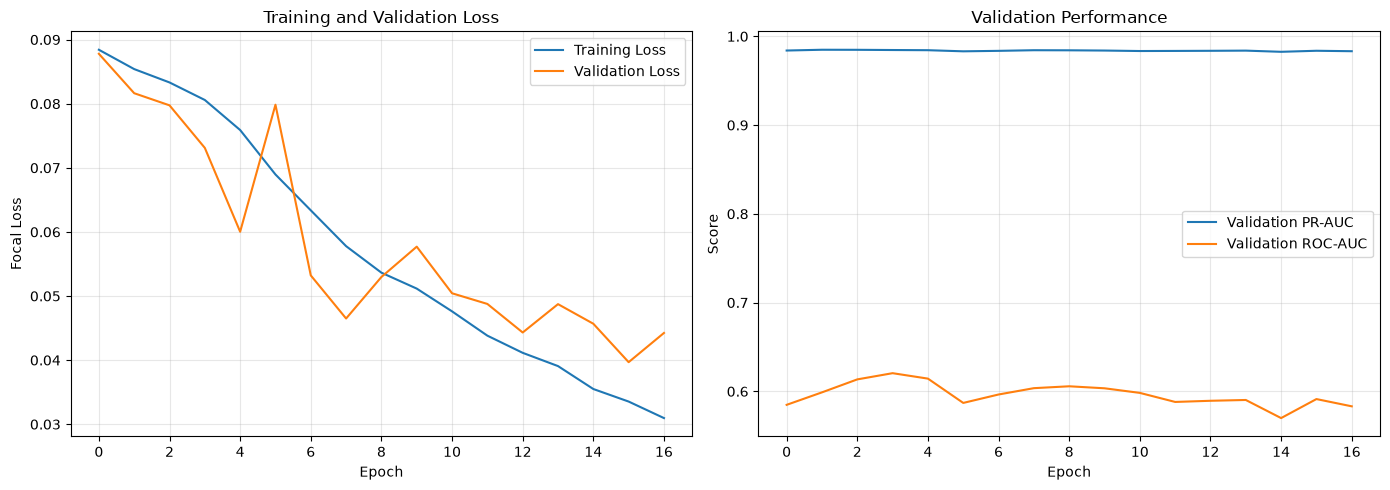

In [22]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

axes[0].plot(
    history["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Focal Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history["val_pr_auc"],
    label="Validation PR-AUC"
)

axes[1].plot(
    history["val_roc_auc"],
    label="Validation ROC-AUC"
)

axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
checkpoint_path = "task1_syphilis/checkpoints/best_model.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Best model checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation PR-AUC:", checkpoint["best_val_pr_auc"])

Best model checkpoint loaded successfully!
Best epoch: 2
Best validation PR-AUC: 0.9848948992223215


VALIDATION RESULTS
---------------------------------------------
ROC-AUC:           0.5989
Average Precision: 0.9849
Balanced Accuracy: 0.5624

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0     0.0255    0.5424    0.0488       118
     Class 1     0.9844    0.5823    0.7318      5847

    accuracy                         0.5816      5965
   macro avg     0.5050    0.5624    0.3903      5965
weighted avg     0.9654    0.5816    0.7183      5965



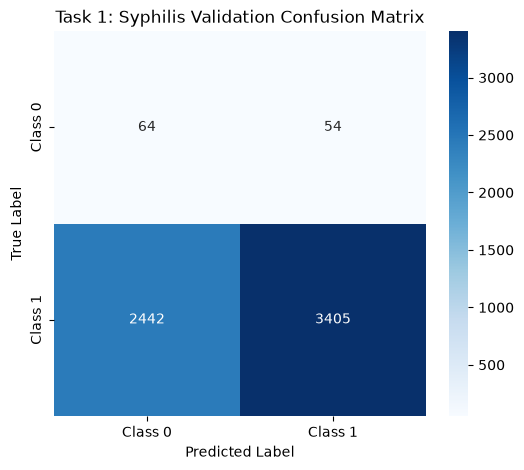

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

# Evaluate the restored best model
val_metrics, y_true, y_prob = evaluate_model(
    model, val_loader, criterion
)

# Predictions at threshold 0.5
y_pred = (y_prob >= 0.5).astype(int)

print("VALIDATION RESULTS")
print("-" * 45)
print(f"ROC-AUC:           {roc_auc_score(y_true, y_prob):.4f}")
print(f"Average Precision: {average_precision_score(y_true, y_prob):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Class 0", "Class 1"],
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Task 1: Syphilis Validation Confusion Matrix")
plt.show()

MINORITY CLASS (CLASS 0) PERFORMANCE
---------------------------------------------
Class 0 Average Precision: 0.0318
Class 0 ROC-AUC:            0.5989
Class 0 prevalence:         0.0198


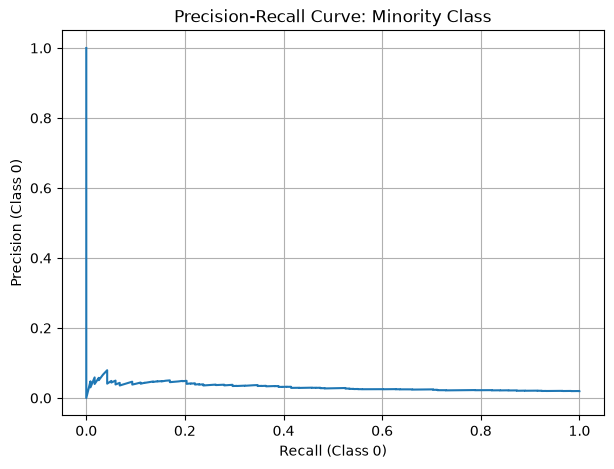

In [30]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Evaluate Class 0 as the positive/minority class
y_true_class0 = (y_true == 0).astype(int)

# Probability assigned to Class 0
y_prob_class0 = 1 - y_prob

class0_ap = average_precision_score(
    y_true_class0,
    y_prob_class0
)

class0_roc = roc_auc_score(
    y_true_class0,
    y_prob_class0
)

print("MINORITY CLASS (CLASS 0) PERFORMANCE")
print("-" * 45)
print(f"Class 0 Average Precision: {class0_ap:.4f}")
print(f"Class 0 ROC-AUC:            {class0_roc:.4f}")
print(f"Class 0 prevalence:         {y_true_class0.mean():.4f}")

# Precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    y_true_class0,
    y_prob_class0
)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall (Class 0)")
plt.ylabel("Precision (Class 0)")
plt.title("Precision-Recall Curve: Minority Class")
plt.grid(True)
plt.show()

Probability statistics by actual class:
             Probability_Class_0                                          \
                           count    mean     std     min     25%     50%   
Actual_Class                                                               
0                          118.0  0.5003  0.0414  0.3882  0.4719  0.5057   
1                         5847.0  0.4869  0.0401  0.3428  0.4600  0.4907   

                             Probability_Class_1                          \
                 75%     max               count    mean     std     min   
Actual_Class                                                               
0             0.5307  0.5767               118.0  0.4997  0.0414  0.4233   
1             0.5156  0.5955              5847.0  0.5131  0.0401  0.4045   

                                              
                 25%     50%     75%     max  
Actual_Class                                  
0             0.4693  0.4943  0.5281  0.6118  
1         

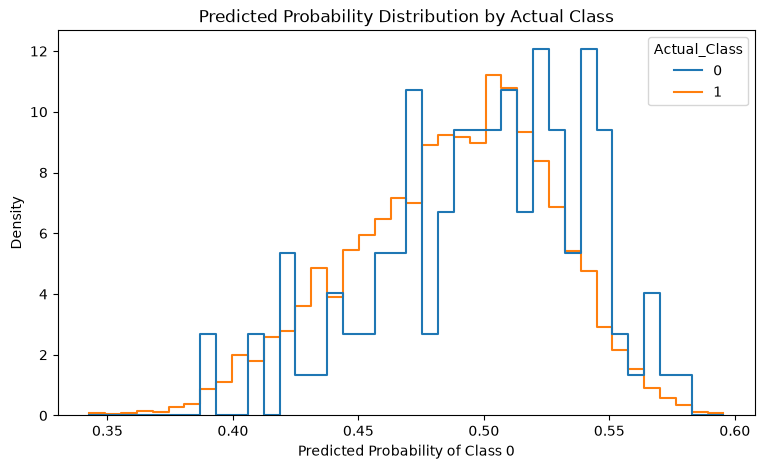

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create a prediction analysis dataframe
prediction_df = pd.DataFrame({
    "Actual_Class": y_true,
    "Probability_Class_0": 1 - y_prob,
    "Probability_Class_1": y_prob
})

print("Probability statistics by actual class:")
print(
    prediction_df.groupby("Actual_Class")[
        ["Probability_Class_0", "Probability_Class_1"]
    ].describe().round(4)
)

# Plot predicted probability distributions
plt.figure(figsize=(9, 5))

sns.histplot(
    data=prediction_df,
    x="Probability_Class_0",
    hue="Actual_Class",
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.xlabel("Predicted Probability of Class 0")
plt.ylabel("Density")
plt.title("Predicted Probability Distribution by Actual Class")
plt.show()

In [32]:
import pandas as pd
import numpy as np

# Use the original dataframe
print("Target distribution:")
print(df["VDRL_RESULT"].value_counts(dropna=False))

print("\nFeature statistics by target class:")

# Numerical feature
print("\nAGE distribution:")
print(
    df.groupby("VDRL_RESULT")["AGE"]
      .agg(["count", "mean", "std", "min", "median", "max"])
)

# Categorical feature distributions
categorical_cols = [
    col for col in FEATURE_COLS
    if col not in NUMERIC_COLS
]

for col in categorical_cols:
    print(f"\n--- {col} ---")

    distribution = pd.crosstab(
        df[col],
        df["VDRL_RESULT"],
        normalize="columns"
    )

    print(distribution.round(3))

Target distribution:
VDRL_RESULT
1    40936
0      826
Name: count, dtype: int64

Feature statistics by target class:

AGE distribution:
             count       mean       std  min  median   max
VDRL_RESULT                                               
0              826  24.929782  4.692215  0.0    25.0  48.0
1            40935  25.197704  4.556848  0.0    25.0  51.0

--- CONS_ALCOHOL ---
VDRL_RESULT       0      1
CONS_ALCOHOL              
0.0           0.073  0.029
1.0           0.828  0.871
2.0           0.099  0.099

--- RH_FACTOR ---
VDRL_RESULT      0      1
RH_FACTOR                
0.0          0.542  0.618
1.0          0.045  0.052
2.0          0.413  0.330

--- SMOKER ---
VDRL_RESULT      0      1
SMOKER                   
0.0          0.094  0.034
1.0          0.828  0.890
2.0          0.077  0.076

--- PLAN_PREGNANCY ---
VDRL_RESULT         0      1
PLAN_PREGNANCY              
0.0             0.332  0.403
1.0             0.631  0.546
2.0             0.038  0.051

--- B

In [33]:
# Check unique values for every categorical feature

for col in categorical_cols:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

print("\nTarget encoding:")
print(df["VDRL_RESULT"].value_counts().sort_index())

print("\nDuplicate records:")
print("Exact duplicate rows:", df.duplicated().sum())

print("\nDataset dimensions:")
print("Rows:", df.shape[0])
print("Features:", df.shape[1] - 1)

CONS_ALCOHOL: [0.0, 1.0, 2.0]
RH_FACTOR: [0.0, 1.0, 2.0]
SMOKER: [0.0, 1.0, 2.0]
PLAN_PREGNANCY: [0.0, 1.0, 2.0]
BLOOD_GROUP: [0.0, 1.0, 2.0, 3.0, 4.0]
HAS_PREG_RISK: [0.0, 1.0, 2.0]
TET_VACCINE: [0.0, 1.0, 2.0]
IS_HEAD_FAMILY: [0.0, 1.0, 2.0]
MARITAL_STATUS: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
FOOD_INSECURITY: [0.0, 1.0, 2.0]
NUM_ABORTIONS: [0.0, 1.0, 2.0, 3.0]
NUM_LIV_CHILDREN: [0.0, 1.0, 2.0, 3.0, 4.0]
NUM_PREGNANCIES: [0.0, 1.0, 2.0, 3.0, 4.0]
FAM_PLANNING: [0.0, 1.0, 2.0]
TYPE_HOUSE: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
HAS_FAM_INCOME: [0.0, 1.0]
LEVEL_SCHOOLING: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]
CONN_SEWER_NET: [0.0, 1.0, 2.0]
NUM_RES_HOUSEHOLD: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
HAS_FRU_TREE: [0.0, 1.0, 2.0]
HAS_VEG_GARDEN: [0.0, 1.0, 2.0]
FAM_INCOME: [0.0, 1.0, 2.0, 3.0]
HOUSING_STATUS: [0.0, 1.0, 2.0, 3.0]
WATER_TREATMENT: [0.0, 1.0, 2.0, 3.0, 4.0]

Target encoding:
VDRL_RESULT
0      826
1    40936
Name: count, dtype: int64

Duplicate records:
Exact duplicate rows: 833

Dat

In [34]:
# Separate feature columns and target
feature_cols = [c for c in df.columns if c != "VDRL_RESULT"]

# Identify duplicated feature combinations
duplicate_mask = df.duplicated(
    subset=feature_cols,
    keep=False
)

duplicate_df = df[duplicate_mask].copy()

print("Records involved in duplicate feature combinations:",
      len(duplicate_df))

print("\nTarget distribution among duplicate records:")
print(duplicate_df["VDRL_RESULT"].value_counts())

# Check conflicting labels
conflicting_groups = (
    duplicate_df.groupby(feature_cols)["VDRL_RESULT"]
    .nunique()
)

conflicting_groups = conflicting_groups[
    conflicting_groups > 1
]

print("\nFeature combinations with conflicting target labels:",
      len(conflicting_groups))

Records involved in duplicate feature combinations: 1589

Target distribution among duplicate records:
VDRL_RESULT
1    1562
0      27
Name: count, dtype: int64

Feature combinations with conflicting target labels: 17


In [35]:
# Identify the 17 conflicting feature combinations

conflict_keys = conflicting_groups.index

conflict_records = df.merge(
    pd.DataFrame(
        list(conflict_keys),
        columns=feature_cols
    ),
    on=feature_cols,
    how="inner"
)

print("Conflicting records:", len(conflict_records))

for i, (_, group) in enumerate(
    conflict_records.groupby(feature_cols, dropna=False),
    start=1
):
    print(f"\nConflict Group {i}")
    print("Number of records:", len(group))
    print("Target distribution:")
    print(group["VDRL_RESULT"].value_counts().to_dict())

Conflicting records: 52

Conflict Group 1
Number of records: 2
Target distribution:
{0: 1, 1: 1}

Conflict Group 2
Number of records: 3
Target distribution:
{1: 2, 0: 1}

Conflict Group 3
Number of records: 2
Target distribution:
{0: 1, 1: 1}

Conflict Group 4
Number of records: 2
Target distribution:
{1: 1, 0: 1}

Conflict Group 5
Number of records: 2
Target distribution:
{1: 1, 0: 1}

Conflict Group 6
Number of records: 3
Target distribution:
{1: 2, 0: 1}

Conflict Group 7
Number of records: 2
Target distribution:
{1: 1, 0: 1}

Conflict Group 8
Number of records: 8
Target distribution:
{1: 7, 0: 1}

Conflict Group 9
Number of records: 2
Target distribution:
{0: 1, 1: 1}

Conflict Group 10
Number of records: 2
Target distribution:
{1: 1, 0: 1}

Conflict Group 11
Number of records: 2
Target distribution:
{1: 1, 0: 1}

Conflict Group 12
Number of records: 2
Target distribution:
{1: 1, 0: 1}

Conflict Group 13
Number of records: 2
Target distribution:
{0: 1, 1: 1}

Conflict Group 14
Numb

In [36]:
# Number of conflicting records by class
conflict_class_counts = conflict_records["VDRL_RESULT"].value_counts()

# Total records in each class
total_class_counts = df["VDRL_RESULT"].value_counts()

print("Conflicting records by class:")
print(conflict_class_counts)

print("\nPercentage of each class involved in conflicts:")

for cls in sorted(total_class_counts.index):
    conflict_count = conflict_class_counts.get(cls, 0)
    total_count = total_class_counts[cls]

    percentage = (conflict_count / total_count) * 100

    print(
        f"Class {cls}: {conflict_count}/{total_count} "
        f"({percentage:.2f}%)"
    )

Conflicting records by class:
VDRL_RESULT
1    35
0    17
Name: count, dtype: int64

Percentage of each class involved in conflicts:
Class 0: 17/826 (2.06%)
Class 1: 35/40936 (0.09%)


In [37]:
%pip install catboost

  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 MB 90.1 MB/s  0:00:01s eta 0:00:010:00:01
Using cached graphviz-0.21-py3-none-any.whl (47 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 76.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [catboost]━━━━━━━━━ 2/3 [catboost]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [38]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)
import numpy as np
import pandas as pd

# Use the existing split indices
X_train_cb = df.iloc[train_idx][FEATURE_COLS].copy()
X_val_cb   = df.iloc[val_idx][FEATURE_COLS].copy()
X_test_cb  = df.iloc[test_idx][FEATURE_COLS].copy()

y_train_cb = df.iloc[train_idx][TARGET_COL].astype(int)
y_val_cb   = df.iloc[val_idx][TARGET_COL].astype(int)
y_test_cb  = df.iloc[test_idx][TARGET_COL].astype(int)

# Treat all features as categorical except AGE
cat_features = [
    col for col in FEATURE_COLS
    if col != "AGE"
]

# Convert categorical values to strings
for data in [X_train_cb, X_val_cb, X_test_cb]:
    for col in cat_features:
        data[col] = data[col].astype(str)

print("Training shape:", X_train_cb.shape)
print("Validation shape:", X_val_cb.shape)
print("Test shape:", X_test_cb.shape)

print("\nTraining class distribution:")
print(y_train_cb.value_counts())

Training shape: (29830, 25)
Validation shape: (5965, 25)
Test shape: (5967, 25)

Training class distribution:
VDRL_RESULT
1    29256
0      574
Name: count, dtype: int64


In [39]:
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100,
    early_stopping_rounds=100,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cb,
    y_train_cb,
    cat_features=cat_features,
    eval_set=(X_val_cb, y_val_cb),
    use_best_model=True
)

print("\nBest iteration:", catboost_model.best_iteration_)
print("Best validation AUC:", catboost_model.best_score_["validation"]["AUC"])

0:	test: 0.5472153	best: 0.5472153 (0)	total: 110ms	remaining: 1m 50s
100:	test: 0.6405397	best: 0.6413915 (92)	total: 1.08s	remaining: 9.64s
200:	test: 0.6514366	best: 0.6514366 (199)	total: 1.92s	remaining: 7.62s
300:	test: 0.6447202	best: 0.6525893 (212)	total: 2.74s	remaining: 6.37s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.6525893224
bestIteration = 212

Shrink model to first 213 iterations.

Best iteration: 212
Best validation AUC: 0.6525893223980509


In [40]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

# Predict probabilities
val_probs = catboost_model.predict_proba(X_val_cb)[:, 1]

# Convert probabilities to Class 0 probabilities
val_probs_class0 = 1 - val_probs

# Treat Class 0 as the positive class for evaluation
y_val_class0 = (y_val_cb == 0).astype(int)

# Default threshold: 0.5
val_preds = (val_probs >= 0.5).astype(int)
val_preds_class0 = (val_preds == 0).astype(int)

print("ROC-AUC:", roc_auc_score(y_val_class0, val_probs_class0))

print(
    "Class 0 Average Precision:",
    average_precision_score(y_val_class0, val_probs_class0)
)

print(
    "Class 0 prevalence:",
    y_val_class0.mean()
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_val_class0, val_preds_class0)
)

print("\nClassification Report:")
print(
    classification_report(
        y_val_class0,
        val_preds_class0,
        target_names=["Class 1", "Class 0"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_class0, val_preds_class0))

ROC-AUC: 0.652589322398051
Class 0 Average Precision: 0.05271667411966625
Class 0 prevalence: 0.02196144174350377
Balanced Accuracy: 0.6262891656438828

Classification Report:
              precision    recall  f1-score   support

     Class 1       0.99      0.69      0.81      5834
     Class 0       0.04      0.56      0.07       131

    accuracy                           0.68      5965
   macro avg       0.51      0.63      0.44      5965
weighted avg       0.97      0.68      0.79      5965


Confusion Matrix:
[[4012 1822]
 [  57   74]]


In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Class 0 probability
val_probs_class0 = 1 - catboost_model.predict_proba(X_val_cb)[:, 1]

# Actual Class 0 labels
y_val_class0 = (y_val_cb == 0).astype(int)

thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90]

threshold_results = []

for threshold in thresholds:
    predictions = (val_probs_class0 >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_class0, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_class0, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_class0, predictions, zero_division=0
        ),
        "Predicted Class 0": predictions.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  Predicted Class 0
      0.50     0.0390  0.5649    0.0730               1896
      0.55     0.0465  0.3359    0.0816                947
      0.60     0.0600  0.1832    0.0904                400
      0.65     0.0534  0.0534    0.0534                131
      0.70     0.0769  0.0229    0.0353                 39
      0.75     0.1429  0.0076    0.0145                  7
      0.80     0.0000  0.0000    0.0000                  0
      0.85     0.0000  0.0000    0.0000                  0
      0.90     0.0000  0.0000    0.0000                  0


          Feature  Importance
   PLAN_PREGNANCY    8.931938
  FOOD_INSECURITY    8.535258
  LEVEL_SCHOOLING    7.117476
      TET_VACCINE    6.572209
   MARITAL_STATUS    5.456389
    NUM_ABORTIONS    5.342971
   HOUSING_STATUS    5.065056
       FAM_INCOME    4.715993
   HAS_VEG_GARDEN    4.605599
      BLOOD_GROUP    4.480709
        RH_FACTOR    4.427283
     FAM_PLANNING    4.383489
   IS_HEAD_FAMILY    4.359029
   CONN_SEWER_NET    3.394568
    HAS_PREG_RISK    3.285011
           SMOKER    3.097271
NUM_RES_HOUSEHOLD    3.067758
              AGE    2.701311
     HAS_FRU_TREE    2.084350
  WATER_TREATMENT    1.648990
 NUM_LIV_CHILDREN    1.472552
   HAS_FAM_INCOME    1.456871
     CONS_ALCOHOL    1.369672
  NUM_PREGNANCIES    1.243524
       TYPE_HOUSE    1.184721


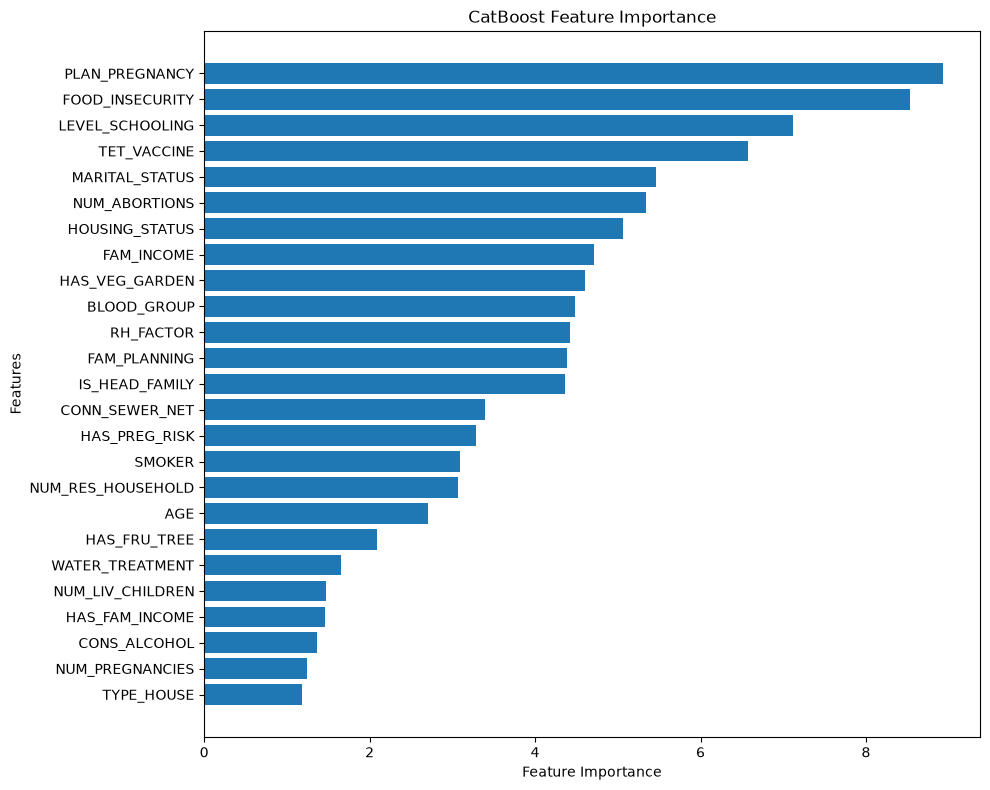

In [42]:
importance_df = pd.DataFrame({
    "Feature": FEATURE_COLS,
    "Importance": catboost_model.get_feature_importance()
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print(importance_df.to_string(index=False))

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("CatBoost Feature Importance")
plt.tight_layout()
plt.show()

In [43]:
%pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 88.1 MB/s  0:00:00s eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 59.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [shap]━━━━━━ 4/5 [shap]]te]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/tmp/ipykernel_3419788/3381098481.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


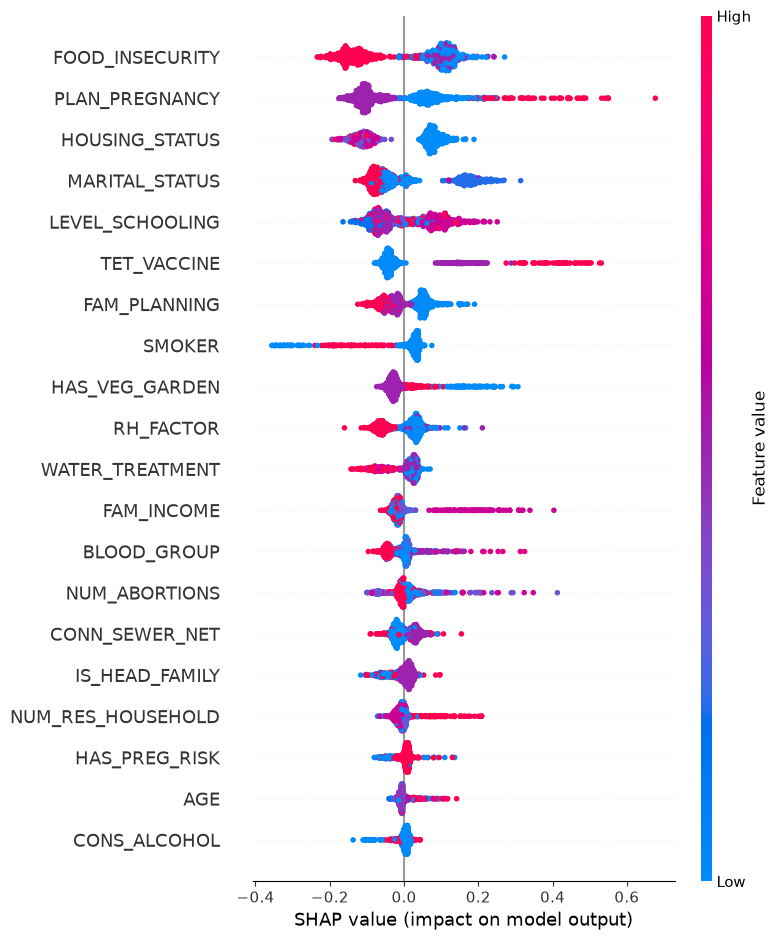

In [44]:
import shap
import matplotlib.pyplot as plt

# Use a manageable validation sample
X_shap = X_val_cb.sample(
    n=min(1000, len(X_val_cb)),
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(catboost_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

# Summary plot
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20
)

In [45]:
from catboost import CatBoostClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# Feature subsets ranked by the existing CatBoost importance
ranked_features = importance_df["Feature"].tolist()

feature_subsets = {
    "Top 10": ranked_features[:10],
    "Top 15": ranked_features[:15],
    "Top 20": ranked_features[:20],
    "All 25": ranked_features
}

subset_results = []

for subset_name, selected_features in feature_subsets.items():

    categorical_subset = [
        col for col in selected_features if col != "AGE"
    ]

    model_subset = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False,
        early_stopping_rounds=100,
        allow_writing_files=False
    )

    model_subset.fit(
        X_train_cb[selected_features],
        y_train_cb,
        cat_features=categorical_subset,
        eval_set=(
            X_val_cb[selected_features],
            y_val_cb
        ),
        use_best_model=True,
        verbose=False
    )

    # Class 0 probability
    probabilities = 1 - model_subset.predict_proba(
        X_val_cb[selected_features]
    )[:, 1]

    actual_class0 = (y_val_cb == 0).astype(int)

    predictions = (probabilities >= 0.5).astype(int)

    subset_results.append({
        "Feature Set": subset_name,
        "Number of Features": len(selected_features),
        "Best Iteration": model_subset.best_iteration_,
        "ROC-AUC": roc_auc_score(actual_class0, probabilities),
        "Class 0 AP": average_precision_score(
            actual_class0, probabilities
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            actual_class0, predictions
        ),
        "Class 0 Precision": precision_score(
            actual_class0, predictions, zero_division=0
        ),
        "Class 0 Recall": recall_score(
            actual_class0, predictions, zero_division=0
        ),
        "Class 0 F1": f1_score(
            actual_class0, predictions, zero_division=0
        )
    })

subset_results_df = pd.DataFrame(subset_results)

print(
    subset_results_df.round(4).to_string(index=False)
)

Feature Set  Number of Features  Best Iteration  ROC-AUC  Class 0 AP  Balanced Accuracy  Class 0 Precision  Class 0 Recall  Class 0 F1
     Top 10                  10             139   0.6551      0.0458             0.6020             0.0330          0.5954      0.0626
     Top 15                  15             184   0.6469      0.0497             0.6107             0.0345          0.5954      0.0652
     Top 20                  20             249   0.6534      0.0493             0.6261             0.0378          0.5878      0.0711
     All 25                  25             259   0.6649      0.0540             0.6278             0.0394          0.5649      0.0737


In [47]:
import inspect

print("Available model and training-related functions:\n")

for name, obj in globals().copy().items():
    if inspect.isfunction(obj):
        if any(word in name.lower() for word in [
            "train", "evaluate", "fit", "loss", "model"
        ]):
            print(f"{name}{inspect.signature(obj)}")

Available model and training-related functions:

train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)
evaluate_model(model, loader, criterion)


In [48]:
print(inspect.signature(SyphilisTabularModel))

(category_cardinalities, hidden_dim=128, representation_dim=128, dropout=0.3)


In [49]:
print("Available variables:\n")

required_variables = [
    "X_train_cat", "X_val_cat", "X_test_cat",
    "X_train_num", "X_val_num", "X_test_num",
    "y_train", "y_val", "y_test",
    "cardinalities", "CAT_COLS", "NUMERIC_COLS",
    "train_loader", "val_loader", "test_loader",
    "DEVICE"
]

for name in required_variables:
    if name in globals():
        value = globals()[name]

        if hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}")
        elif hasattr(value, "dataset"):
            print(f"{name}: samples={len(value.dataset)}")
        else:
            print(f"{name}: {value}")
    else:
        print(f"{name}: NOT FOUND")

Available variables:

X_train_cat: shape=(29830, 24)
X_val_cat: shape=(5965, 24)
X_test_cat: shape=(5967, 24)
X_train_num: NOT FOUND
X_val_num: NOT FOUND
X_test_num: NOT FOUND
y_train: shape=(29830,)
y_val: shape=(5965,)
y_test: shape=(5967,)
cardinalities: NOT FOUND
CAT_COLS: NOT FOUND
NUMERIC_COLS: ['AGE']
train_loader: samples=29830
val_loader: samples=5965
test_loader: samples=5967
DEVICE: cuda


In [50]:
print("\nModel class:", SyphilisTabularModel)
print("Model parameters:", inspect.signature(SyphilisTabularModel))


Model class: <class '__main__.SyphilisTabularModel'>
Model parameters: (category_cardinalities, hidden_dim=128, representation_dim=128, dropout=0.3)


In [51]:
print("MODEL ARCHITECTURE")
print(model)

print("\nMODEL STATE DICTIONARY")
for name, parameter in model.state_dict().items():
    print(name, tuple(parameter.shape))

print("\nTRAINING DATASET")
print("Categorical input shape:", train_loader.dataset.tensors[0].shape)
print("Age input shape:", train_loader.dataset.tensors[1].shape)
print("Target shape:", train_loader.dataset.tensors[2].shape)

print("\nVALIDATION DATASET")
print("Categorical input shape:", val_loader.dataset.tensors[0].shape)
print("Age input shape:", val_loader.dataset.tensors[1].shape)
print("Target shape:", val_loader.dataset.tensors[2].shape)

print("\nCHECKPOINT FILES")
import os

for root, dirs, files in os.walk("task1_syphilis"):
    for file in files:
        print(os.path.join(root, file))

MODEL ARCHITECTURE
SyphilisTabularModel(
  (embeddings): ModuleList(
    (0-3): 4 x Embedding(4, 4, padding_idx=0)
    (4): Embedding(6, 4, padding_idx=0)
    (5-7): 3 x Embedding(4, 4, padding_idx=0)
    (8): Embedding(7, 4, padding_idx=0)
    (9): Embedding(4, 4, padding_idx=0)
    (10): Embedding(5, 4, padding_idx=0)
    (11-12): 2 x Embedding(6, 4, padding_idx=0)
    (13): Embedding(4, 4, padding_idx=0)
    (14): Embedding(7, 4, padding_idx=0)
    (15): Embedding(3, 4, padding_idx=0)
    (16): Embedding(11, 4, padding_idx=0)
    (17): Embedding(4, 4, padding_idx=0)
    (18): Embedding(7, 4, padding_idx=0)
    (19-20): 2 x Embedding(4, 4, padding_idx=0)
    (21-22): 2 x Embedding(5, 4, padding_idx=0)
    (23): Embedding(6, 4, padding_idx=0)
  )
  (age_projection): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
  )
  (representation): Sequential(
    (0): Linear(in_features=112, out_features=128, bias=True)
    (1): LayerNorm((128,), eps=1e-05,

In [52]:
import torch
import os
import inspect

checkpoint_path = "task1_syphilis/checkpoints/best_model.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

# Restore the best previously trained weights
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

# Recover embedding cardinalities directly from the architecture
category_cardinalities = [
    embedding.num_embeddings
    for embedding in model.embeddings
]

print("Checkpoint restored successfully.")
print("Best previous epoch:", checkpoint["epoch"])
print("Previous best validation PR-AUC:", checkpoint["best_val_pr_auc"])

print("\nNumber of categorical features:", len(category_cardinalities))
print("Category cardinalities:", category_cardinalities)

print("\nExisting focal loss:")
print(inspect.signature(BinaryFocalLoss))

print("\nTraining configuration:")
print("Device:", DEVICE)
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))

Checkpoint restored successfully.
Best previous epoch: 2
Previous best validation PR-AUC: 0.9848948992223215

Number of categorical features: 24
Category cardinalities: [4, 4, 4, 4, 6, 4, 4, 4, 7, 4, 5, 6, 6, 4, 7, 3, 11, 4, 7, 4, 4, 5, 5, 6]

Existing focal loss:
(alpha=0.5, gamma=2.0, reduction='mean')

Training configuration:
Device: cuda
Training samples: 29830
Validation samples: 5965


In [53]:
import os
import copy
import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Fine-tuning config

EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 10

criterion = BinaryFocalLoss(
    alpha=0.5,
    gamma=2.0,
    reduction="mean"
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Save separately from the original checkpoint
save_dir = "task1_syphilis/fine_tuned"
os.makedirs(save_dir, exist_ok=True)

best_checkpoint_path = os.path.join(
    save_dir, "best_model.pt"
)


# Validation function

def evaluate_class0(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    all_targets = []
    all_probabilities = []

    with torch.no_grad():

        for cat_x, age_x, targets in loader:

            cat_x = cat_x.to(DEVICE)
            age_x = age_x.to(DEVICE)
            targets = targets.float().to(DEVICE)

            logits = model(cat_x, age_x)

            loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)

            probabilities_class1 = torch.sigmoid(logits)
            probabilities_class0 = 1.0 - probabilities_class1

            all_targets.extend(
                (targets == 0).cpu().numpy()
            )

            all_probabilities.extend(
                probabilities_class0.cpu().numpy()
            )

    y_true = np.asarray(all_targets, dtype=int)
    y_prob = np.asarray(all_probabilities)

    return {
        "loss": total_loss / len(loader.dataset),
        "ap_class0": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "probabilities": y_prob,
        "targets": y_true
    }



best_val_ap = -1.0
best_epoch = 0
patience_counter = 0

history = []

print("Starting neural-network fine-tuning...\n")

for epoch in range(1, EPOCHS + 1):

    model.train()

    running_loss = 0.0

    for cat_x, age_x, targets in train_loader:

        cat_x = cat_x.to(DEVICE)
        age_x = age_x.to(DEVICE)
        targets = targets.float().to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(cat_x, age_x)

        loss = criterion(logits, targets)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * targets.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # Validation
    val_metrics = evaluate_class0(
        model, val_loader, criterion
    )

    val_ap = val_metrics["ap_class0"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_class0_ap": val_ap,
        "val_roc_auc": val_metrics["roc_auc"]
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Class 0 AP: {val_ap:.4f} | "
        f"ROC-AUC: {val_metrics['roc_auc']:.4f}"
    )

    # Save best checkpoint using minority-class AP
    if val_ap > best_val_ap:

        best_val_ap = val_ap
        best_epoch = epoch
        patience_counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_class0_ap": best_val_ap,
            "history": history
        }, best_checkpoint_path)

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break




best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.to(DEVICE)
model.eval()

history_df = pd.DataFrame(history)

print("\nFine-tuning completed.")
print("Best epoch:", best_epoch)
print("Best validation Class 0 AP:", round(best_val_ap, 4))
print("Saved checkpoint:", best_checkpoint_path)

Starting neural-network fine-tuning...

Epoch 01/50 | Train Loss: 0.0840 | Val Loss: 0.0797 | Class 0 AP: 0.0344 | ROC-AUC: 0.6105
Epoch 02/50 | Train Loss: 0.0828 | Val Loss: 0.0808 | Class 0 AP: 0.0348 | ROC-AUC: 0.6121
Epoch 03/50 | Train Loss: 0.0819 | Val Loss: 0.0763 | Class 0 AP: 0.0358 | ROC-AUC: 0.6173
Epoch 04/50 | Train Loss: 0.0809 | Val Loss: 0.0787 | Class 0 AP: 0.0361 | ROC-AUC: 0.6123
Epoch 05/50 | Train Loss: 0.0796 | Val Loss: 0.0787 | Class 0 AP: 0.0376 | ROC-AUC: 0.6194
Epoch 06/50 | Train Loss: 0.0785 | Val Loss: 0.0777 | Class 0 AP: 0.0379 | ROC-AUC: 0.6158
Epoch 07/50 | Train Loss: 0.0773 | Val Loss: 0.0749 | Class 0 AP: 0.0391 | ROC-AUC: 0.6140
Epoch 08/50 | Train Loss: 0.0751 | Val Loss: 0.0697 | Class 0 AP: 0.0380 | ROC-AUC: 0.6083
Epoch 09/50 | Train Loss: 0.0736 | Val Loss: 0.0723 | Class 0 AP: 0.0374 | ROC-AUC: 0.6055
Epoch 10/50 | Train Loss: 0.0722 | Val Loss: 0.0710 | Class 0 AP: 0.0372 | ROC-AUC: 0.6026
Epoch 11/50 | Train Loss: 0.0709 | Val Loss: 0.077

In [54]:
import os
import copy
import torch
import numpy as np
import pandas as pd

# Original checkpoint: every experiment starts from the same weights
original_checkpoint = torch.load(
    "task1_syphilis/checkpoints/best_model.pt",
    map_location=DEVICE,
    weights_only=False
)

experiments = [
    {"name": "A", "lr": 5e-5, "gamma": 1.0, "weight_decay": 1e-4},
    {"name": "B", "lr": 1e-4, "gamma": 1.0, "weight_decay": 1e-4},
    {"name": "C", "lr": 1e-4, "gamma": 2.0, "weight_decay": 1e-4},
    {"name": "D", "lr": 3e-4, "gamma": 2.0, "weight_decay": 1e-4}
]

MAX_EPOCHS = 30
PATIENCE = 7

tuning_dir = "task1_syphilis/hyperparameter_tuning"
os.makedirs(tuning_dir, exist_ok=True)

tuning_results = []
global_best_ap = -1.0
global_best_path = None

for config in experiments:

    print(f"\n{'='*55}")
    print(f"Experiment {config['name']}: {config}")
    print(f"{'='*55}")

    # Restore original model weights
    model.load_state_dict(original_checkpoint["model_state_dict"])
    model.to(DEVICE)

    criterion_trial = BinaryFocalLoss(
        alpha=0.5,
        gamma=config["gamma"],
        reduction="mean"
    )

    optimizer_trial = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )

    best_ap = -1.0
    best_epoch_trial = 0
    patience_counter = 0

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        total_loss = 0.0

        for cat_x, age_x, targets in train_loader:

            cat_x = cat_x.to(DEVICE)
            age_x = age_x.to(DEVICE)
            targets = targets.float().to(DEVICE)

            optimizer_trial.zero_grad(set_to_none=True)

            logits = model(cat_x, age_x)
            loss = criterion_trial(logits, targets)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer_trial.step()

            total_loss += loss.item() * targets.size(0)

        train_loss = total_loss / len(train_loader.dataset)

        val_metrics = evaluate_class0(
            model, val_loader, criterion_trial
        )

        val_ap = val_metrics["ap_class0"]

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Class 0 AP: {val_ap:.4f} | "
            f"ROC-AUC: {val_metrics['roc_auc']:.4f}"
        )

        if val_ap > best_ap:

            best_ap = val_ap
            best_epoch_trial = epoch
            patience_counter = 0

            trial_path = os.path.join(
                tuning_dir,
                f"experiment_{config['name']}.pt"
            )

            torch.save({
                "experiment": config,
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(
                    model.state_dict()
                ),
                "best_val_class0_ap": best_ap,
                "val_roc_auc": val_metrics["roc_auc"]
            }, trial_path)

        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping.")
            break

    # Restore best epoch for this experiment
    trial_checkpoint = torch.load(
        trial_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(trial_checkpoint["model_state_dict"])
    model.eval()

    final_val = evaluate_class0(
        model, val_loader, criterion_trial
    )

    tuning_results.append({
        "Experiment": config["name"],
        "Learning Rate": config["lr"],
        "Focal Gamma": config["gamma"],
        "Best Epoch": best_epoch_trial,
        "Class 0 AP": best_ap,
        "ROC-AUC": final_val["roc_auc"]
    })

    if best_ap > global_best_ap:

        global_best_ap = best_ap
        global_best_path = trial_path

        torch.save({
            **trial_checkpoint,
            "experiment": config,
            "best_val_class0_ap": best_ap
        }, os.path.join(tuning_dir, "best_overall_model.pt"))

    print(
        f"Experiment {config['name']} best AP: {best_ap:.4f}"
    )

# Display comparison
tuning_results_df = pd.DataFrame(tuning_results)

print("\nFINAL HYPERPARAMETER COMPARISON")
print(
    tuning_results_df.sort_values(
        "Class 0 AP", ascending=False
    ).round(4).to_string(index=False)
)

print("\nBest validation Class 0 AP:", round(global_best_ap, 4))
print("Best checkpoint:", global_best_path)


Experiment A: {'name': 'A', 'lr': 5e-05, 'gamma': 1.0, 'weight_decay': 0.0001}
Epoch 01 | Train Loss: 0.1681 | Class 0 AP: 0.0322 | ROC-AUC: 0.6020
Epoch 02 | Train Loss: 0.1661 | Class 0 AP: 0.0332 | ROC-AUC: 0.6067
Epoch 03 | Train Loss: 0.1646 | Class 0 AP: 0.0341 | ROC-AUC: 0.6111
Epoch 04 | Train Loss: 0.1639 | Class 0 AP: 0.0345 | ROC-AUC: 0.6143
Epoch 05 | Train Loss: 0.1629 | Class 0 AP: 0.0352 | ROC-AUC: 0.6177
Epoch 06 | Train Loss: 0.1607 | Class 0 AP: 0.0358 | ROC-AUC: 0.6203
Epoch 07 | Train Loss: 0.1601 | Class 0 AP: 0.0362 | ROC-AUC: 0.6192
Epoch 08 | Train Loss: 0.1582 | Class 0 AP: 0.0361 | ROC-AUC: 0.6208
Epoch 09 | Train Loss: 0.1566 | Class 0 AP: 0.0374 | ROC-AUC: 0.6186
Epoch 10 | Train Loss: 0.1551 | Class 0 AP: 0.0377 | ROC-AUC: 0.6182
Epoch 11 | Train Loss: 0.1542 | Class 0 AP: 0.0385 | ROC-AUC: 0.6172
Epoch 12 | Train Loss: 0.1525 | Class 0 AP: 0.0378 | ROC-AUC: 0.6157
Epoch 13 | Train Loss: 0.1519 | Class 0 AP: 0.0374 | ROC-AUC: 0.6145
Epoch 14 | Train Loss: 

In [55]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    brier_score_loss
)


# Load the best model (Experiment C)
checkpoint_path = "task1_syphilis/hyperparameter_tuning/experiment_C.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Loaded Experiment C")
print("Best epoch:", checkpoint["epoch"])
print("Best validation Class 0 AP:", checkpoint["best_val_class0_ap"])
val_metrics = evaluate_class0(model, val_loader, criterion)
test_metrics = evaluate_class0(model, test_loader, criterion)

y_val = (val_metrics["targets"] == 0).astype(int)
p_val = val_metrics["probabilities"]

y_test = (test_metrics["targets"] == 0).astype(int)
p_test = test_metrics["probabilities"]



#Selecting threshold using validation data only
precision, recall, thresholds = precision_recall_curve(
    y_val, p_val
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold = float(thresholds[best_idx])

print("\nValidation threshold selection")
print("--------------------------------")
print(f"Selected threshold: {best_threshold:.6f}")
print(f"Validation precision: {precision[best_idx]:.4f}")
print(f"Validation recall:    {recall[best_idx]:.4f}")
print(f"Validation F1:        {f1_values[best_idx]:.4f}")


#  Final evaluation
y_pred = (p_test >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

test_results = {
    "Threshold": best_threshold,
    "Class 0 AP": average_precision_score(y_test, p_test),
    "ROC-AUC": roc_auc_score(y_test, p_test),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "Specificity": tn / (tn + fp + 1e-12),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "MCC": matthews_corrcoef(y_test, y_pred),
    "Brier Score": brier_score_loss(y_test, p_test)
}

print("\nFINAL TEST SET RESULTS")
print("=" * 55)

for metric, value in test_results.items():
    print(f"{metric:22s}: {value:.5f}")

print("\nConfusion Matrix")
print("----------------")
print("Rows = Actual [Class 1, Class 0]")
print("Columns = Predicted [Class 1, Class 0]")
print(np.array([[tn, fp], [fn, tp]]))

print("\nTest-set class counts")
print("---------------------")
print("Actual Class 0:", int(y_test.sum()))
print("Actual Class 1:", int(len(y_test) - y_test.sum()))
print("Predicted Class 0:", int(y_pred.sum()))
print("Predicted Class 1:", int(len(y_pred) - y_pred.sum()))

# Save evaluation results
results_df = pd.DataFrame(
    list(test_results.items()),
    columns=["Metric", "Value"]
)

results_df.to_csv(
    "task1_syphilis/hyperparameter_tuning/final_test_results.csv",
    index=False
)

print("\nSaved test results.")

Loaded Experiment C
Best epoch: 7
Best validation Class 0 AP: 0.03985866983584557

Validation threshold selection
--------------------------------
Selected threshold: 0.213917
Validation precision: 0.9802
Validation recall:    1.0000
Validation F1:        0.9900

FINAL TEST SET RESULTS
Threshold             : 0.21392
Class 0 AP            : 0.97173
ROC-AUC               : 0.38448
Precision             : 0.98022
Recall                : 1.00000
F1-score              : 0.99001
Specificity           : 0.00000
Balanced Accuracy     : 0.50000
MCC                   : 0.00000
Brier Score           : 0.29849

Confusion Matrix
----------------
Rows = Actual [Class 1, Class 0]
Columns = Predicted [Class 1, Class 0]
[[   0  118]
 [   0 5849]]

Test-set class counts
---------------------
Actual Class 0: 5849
Actual Class 1: 118
Predicted Class 0: 5967
Predicted Class 1: 0

Saved test results.


In [56]:
import inspect
import numpy as np

print("EVALUATION FUNCTION")
print("=" * 60)
print(inspect.getsource(evaluate_class0))

print("\nORIGINAL TEST TARGET DISTRIBUTION")
print("=" * 60)

print("test_loader dataset targets:")
print(np.unique(
    test_loader.dataset.tensors[2].cpu().numpy(),
    return_counts=True
))

print("\nEVALUATION OUTPUT TARGET DISTRIBUTION")
print("=" * 60)

raw_targets = np.asarray(test_metrics["targets"])
print("Unique values and counts:")
print(np.unique(raw_targets, return_counts=True))

print("\nPROBABILITY DISTRIBUTION")
print("=" * 60)

print("Min:", np.min(test_metrics["probabilities"]))
print("Max:", np.max(test_metrics["probabilities"]))
print("Mean:", np.mean(test_metrics["probabilities"]))

print("\nPREDICTIONS AT SELECTED THRESHOLD")
print("=" * 60)

print("Threshold:", best_threshold)
print("Predicted above threshold:",
      np.sum(test_metrics["probabilities"] >= best_threshold))

EVALUATION FUNCTION
def evaluate_class0(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    all_targets = []
    all_probabilities = []

    with torch.no_grad():

        for cat_x, age_x, targets in loader:

            cat_x = cat_x.to(DEVICE)
            age_x = age_x.to(DEVICE)
            targets = targets.float().to(DEVICE)

            logits = model(cat_x, age_x)

            loss = criterion(logits, targets)

            total_loss += loss.item() * targets.size(0)

            probabilities_class1 = torch.sigmoid(logits)
            probabilities_class0 = 1.0 - probabilities_class1

            all_targets.extend(
                (targets == 0).cpu().numpy()
            )

            all_probabilities.extend(
                probabilities_class0.cpu().numpy()
            )

    y_true = np.asarray(all_targets, dtype=int)
    y_prob = np.asarray(all_probabilities)

    return {
        "loss": total_loss / len(loader.dataset),
        "ap_class0": average_p

In [58]:
from sklearn.metrics import accuracy_score, f1_score

# Original labels: 0 and 1
y_true = np.asarray(test_metrics["targets"], dtype=int)
y_pred = (
    np.asarray(test_metrics["probabilities"]).reshape(-1)
    >= best_threshold
).astype(int)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

# Report
print("FINAL TEST RESULTS")
print("=" * 35)
print(f"Accuracy       : {accuracy * 100:.2f}%")
print(f"Weighted F1    : {weighted_f1 * 100:.2f}%")

FINAL TEST RESULTS
Accuracy       : 89.66%
Weighted F1    : 92.80%


In [59]:
checkpoint_path = "task1_syphilis/hyperparameter_tuning/experiment_C.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

# Fisher sample
cat_all, age_all, target_all = train_loader.dataset.tensors

target_numpy = target_all.cpu().numpy()

class0_indices = np.where(target_numpy == 0)[0]
class1_indices = np.where(target_numpy == 1)[0]

rng = np.random.default_rng(42)

samples_per_class = min(
    500,
    len(class0_indices),
    len(class1_indices)
)

selected_indices = np.concatenate([
    rng.choice(class0_indices, samples_per_class, replace=False),
    rng.choice(class1_indices, samples_per_class, replace=False)
])

rng.shuffle(selected_indices)

print("Fisher sample size:", len(selected_indices))
print("Class 0 samples:", samples_per_class)
print("Class 1 samples:", samples_per_class)

# diagonal empirical Fisher information
trainable_params = {
    name: param
    for name, param in model.named_parameters()
    if param.requires_grad
}

fisher = {
    name: torch.zeros_like(param, device=DEVICE)
    for name, param in trainable_params.items()
}

for count, idx in enumerate(selected_indices, start=1):

    model.zero_grad(set_to_none=True)

    cat_x = cat_all[idx].unsqueeze(0).to(DEVICE)
    age_x = age_all[idx].unsqueeze(0).to(DEVICE)
    target = target_all[idx].float().to(DEVICE)

    logits = model(cat_x, age_x)
    target = target.view_as(logits)

    loss = F.binary_cross_entropy_with_logits(
        logits,
        target,
        reduction="mean"
    )

    gradients = torch.autograd.grad(
        loss,
        tuple(trainable_params.values()),
        retain_graph=False,
        create_graph=False
    )

    for (name, _), grad in zip(trainable_params.items(), gradients):
        if grad is not None:
            fisher[name] += grad.detach().pow(2)

    if count % 200 == 0:
        print(f"Processed {count}/{len(selected_indices)} samples")

# Average Fisher values
for name in fisher:
    fisher[name] /= len(selected_indices)

theta_star = {
    name: param.detach().clone().cpu()
    for name, param in model.named_parameters()
    if param.requires_grad
}

fisher = {
    name: value.detach().cpu()
    for name, value in fisher.items()
}

model_state = {
    name: value.detach().cpu().clone()
    for name, value in model.state_dict().items()
}

save_dir = "task1_syphilis/final_task1"
os.makedirs(save_dir, exist_ok=True)

final_artifact = {
    "task_name": "Task 1 - VDRL Classification",
    "model_state_dict": model_state,
    "fisher_information": fisher,
    "theta_star": theta_star,
    "category_cardinalities": category_cardinalities,
    "best_epoch": checkpoint["epoch"],
    "best_validation_class0_ap": checkpoint["best_val_class0_ap"],
    "decision_threshold": best_threshold,
    "test_results": results,
    "fisher_sample_size": len(selected_indices),
    "fisher_samples_per_class": samples_per_class,
    "fisher_loss": "Binary Cross Entropy with Logits",
    "fisher_estimation": "Class-balanced diagonal empirical Fisher"
}

artifact_path = os.path.join(
    save_dir,
    "task1_vdrl_model_with_fisher.pt"
)

torch.save(final_artifact, artifact_path)

fisher_summary = []

for name, values in fisher.items():
    fisher_summary.append({
        "Parameter": name,
        "Mean Fisher": values.mean().item(),
        "Maximum Fisher": values.max().item(),
        "Total Fisher": values.sum().item()
    })

fisher_df = pd.DataFrame(fisher_summary)
fisher_df.to_csv(
    os.path.join(save_dir, "fisher_importance_summary.csv"),
    index=False
)

print("\nTASK 1 SAVED SUCCESSFULLY")
print("=" * 55)
print("Model + Fisher:", artifact_path)
print("Fisher summary:", os.path.join(
    save_dir, "fisher_importance_summary.csv"
))
print("Total parameter tensors:", len(fisher))
print("Total trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Mean Fisher importance:", np.mean([
    v.mean().item() for v in fisher.values()
]))

Fisher sample size: 1000
Class 0 samples: 500
Class 1 samples: 500
Processed 200/1000 samples
Processed 400/1000 samples
Processed 600/1000 samples
Processed 800/1000 samples
Processed 1000/1000 samples

TASK 1 SAVED SUCCESSFULLY
Model + Fisher: task1_syphilis/final_task1/task1_vdrl_model_with_fisher.pt
Fisher summary: task1_syphilis/final_task1/fisher_importance_summary.csv
Total parameter tensors: 38
Total trainable parameters: 40329
Mean Fisher importance: 0.006165601476823213
